In [1]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [2]:
from google.colab import userdata
from roboflow import Roboflow

api_key = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)

project = rf.workspace("alpr-udemm").project(
    "egyptian-license-plate"
)

version = project.version(2)

dataset = version.download("yolov11")

print(dataset)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to egyptian-license-plate-2 in yolov11:: 100%|██████████| 1495/1495 [00:00<00:00, 2511.37it/s]

In [3]:
from pathlib import Path

dataset_path = Path(dataset.location)

print(dataset_path)

/content/egyptian-license-plate-2


In [4]:
import yaml
import os
yaml_path = dataset_path / "data.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print(data)

{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['license plate'], 'roboflow': {'workspace': 'alpr-udemm', 'project': 'egyptian-license-plate', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/alpr-udemm/egyptian-license-plate/dataset/2'}}


In [5]:
from pathlib import Path
dataset=Path(dataset.location)
for split in ["train","valid","test"]:
  image_dir=dataset/split/"images"
  if image_dir.exists():
    image=list(image_dir.glob("*"))
    print(f"{split}: {len(image)} image")

train: 522 image
valid: 111 image
test: 112 image


image: /content/egyptian-license-plate-2/test/images/img_272_jpg.rf.b9de28b621c875484adf4f1559d32956.jpg
image size: (780, 1040)


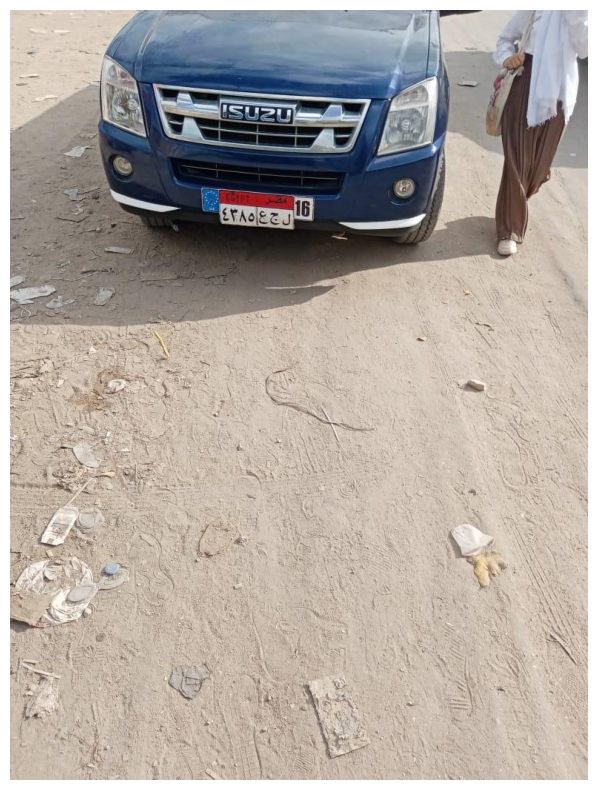

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

image_path = image[0]

image = Image.open(image_path)

print("image:", image_path)
print("image size:", image.size)

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()

In [10]:
from pathlib import Path

label_dir = dataset_path / "train" / "labels"

label_files = list(label_dir.glob("*.txt"))

print("Number of label files:", len(label_files))

print("\nFirst 5 labels:")
for label in label_files[:5]:
    print(label.name)

Number of label files: 522

First 5 labels:
img_590_png.rf.49ca10c7427bb2ebbc48a1ff00d1fb98.txt
img_582_png.rf.ffe9b7bf514a4d314b3f3dcabf39b88d.txt
img_246_jpg.rf.3db3a78a39fdb4e9df5abd800af1113d.txt
img_591_png.rf.7f659cd890c5ac9c84f6d2df9c082773.txt
img_139_jpg.rf.8ee394b316f73420257d932425478d25.txt


In [11]:
label_path = label_files[0]

print("Label:", label_path)

with open(label_path, "r") as f:
    label = f.read()

print("\nLabel content:")
print(label)

Label: /content/egyptian-license-plate-2/train/labels/img_590_png.rf.49ca10c7427bb2ebbc48a1ff00d1fb98.txt

Label content:
0 0.5395833333333333 0.5634375 0.23194444444444445 0.053125


Image: /content/egyptian-license-plate-2/train/images/img_249_jpg.rf.5053990c8e996fd60e5f44395e74086b.jpg
Label: /content/egyptian-license-plate-2/train/labels/img_249_jpg.rf.5053990c8e996fd60e5f44395e74086b.txt
 Label found

Label content:
0 0.4378205128205128 0.31201923076923077 0.16025641025641027 0.09711538461538462


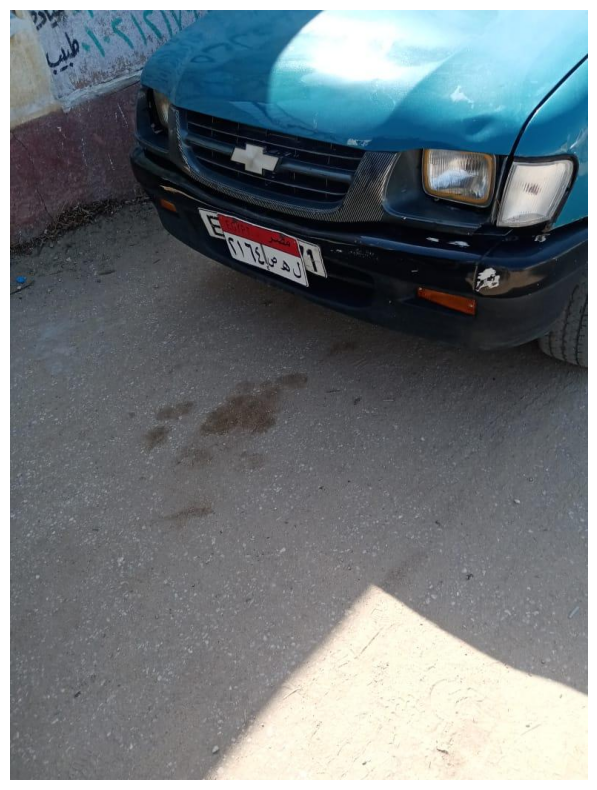

In [14]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

image_dir = dataset_path / "train" / "images"
label_dir = dataset_path / "train" / "labels"

image_files = list(image_dir.glob("*"))
image_path = image_files[0]

image_name = image_path.stem

label_path = label_dir / f"{image_name}.txt"

print("Image:", image_path)
print("Label:", label_path)

if not label_path.exists():
    print(" Label not found")
else:
    print(" Label found")

    image = Image.open(image_path)
    width, height = image.size

    with open(label_path, "r") as f:
        lines = f.readlines()

    print("\nLabel content:")
    print("".join(lines))

    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

Image: /content/egyptian-license-plate-2/train/images/img_249_jpg.rf.5053990c8e996fd60e5f44395e74086b.jpg
Label: /content/egyptian-license-plate-2/train/labels/img_249_jpg.rf.5053990c8e996fd60e5f44395e74086b.txt
Image size: 780 1040


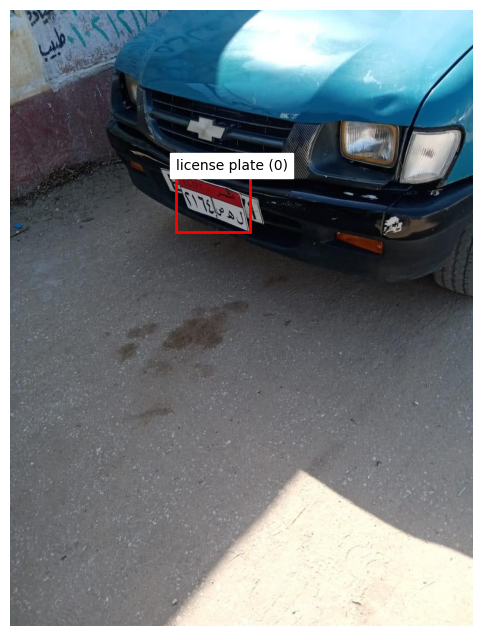

In [16]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_dir = dataset_path / "train" / "images"
label_dir = dataset_path / "train" / "labels"

image_files = list(image_dir.glob("*"))

image_path = image_files[0]

label_path = label_dir / f"{image_path.stem}.txt"

image = Image.open(image_path)
width, height = image.size

print("Image:", image_path)
print("Label:", label_path)
print("Image size:", width, height)

with open(label_path, "r") as f:
    lines = f.readlines()

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(image)


for line in lines:

    class_id, x_center, y_center, box_width, box_height = map(
        float, line.strip().split()
    )

    x_center *= width
    y_center *= height
    box_width *= width
    box_height *= height

    x = x_center - box_width / 2
    y = y_center - box_height / 2

    rect = patches.Rectangle(
        (x, y),
        box_width,
        box_height,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x,
        y - 5,
        f"license plate ({int(class_id)})",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [17]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 12.4 MB/s eta 0:00:00


In [18]:
from ultralytics import YOLO

model = YOLO("yolov8n.yaml")



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [19]:
result= model.train(data=str(yaml_path), epochs=50, imgsz=640,batch=20)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=20, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/egyptian-license-plate-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimiz

In [24]:
metrics= model.val(data=str(yaml_path),split="test")
print(metrics.box.map50)
print(metrics.box.map)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2224.7±355.3 MB/s, size: 103.3 KB)
val: Scanning /content/egyptian-license-plate-2/test/labels.cache... 112 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 112/112 31.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.4it/s 2.9s
                   all        112        114       0.98      0.974      0.983      0.854
Speed: 3.9ms preprocess, 4.5ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/runs/detect/val-3
0.9831096697161691
0.8544995871199857


In [25]:
from pathlib import Path
import matplotlib.pyplot as plt

test_images = list((dataset_path / "test" / "images").glob("*"))

print("Number of test images:", len(test_images))

test_image = test_images[0]

results = model.predict(
    source=str(test_image),
    conf=0.5,
    save=True
)

print("Test image:", test_image)

Number of test images: 112

image 1/1 /content/egyptian-license-plate-2/test/images/img_272_jpg.rf.b9de28b621c875484adf4f1559d32956.jpg: 640x480 1 license plate, 10.9ms
Speed: 1.9ms preprocess, 10.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
Test image: /content/egyptian-license-plate-2/test/images/img_272_jpg.rf.b9de28b621c875484adf4f1559d32956.jpg


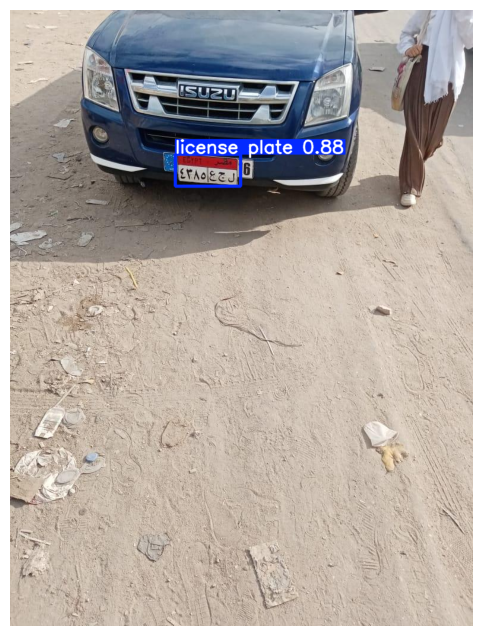

In [26]:
result = results[0]

annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

In [27]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("/content/runs/detect/train/weights/best.pt")

test_images = list((dataset_path / "test" / "images").glob("*"))
image_path = test_images[0]

results = model.predict(
    source=str(image_path),
    conf=0.5
)

result = results[0]

print("Image:", image_path)
print("Number of detections:", len(result.boxes))


image 1/1 /content/egyptian-license-plate-2/test/images/img_272_jpg.rf.b9de28b621c875484adf4f1559d32956.jpg: 640x480 1 license plate, 10.9ms
Speed: 2.0ms preprocess, 10.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
Image: /content/egyptian-license-plate-2/test/images/img_272_jpg.rf.b9de28b621c875484adf4f1559d32956.jpg
Number of detections: 1



image 1/1 /content/egyptian-license-plate-2/test/images/img_272_jpg.rf.b9de28b621c875484adf4f1559d32956.jpg: 640x480 1 license plate, 10.9ms
Speed: 1.9ms preprocess, 10.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


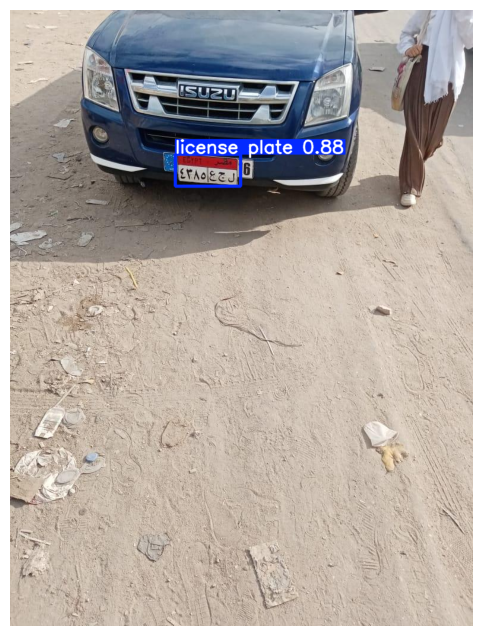

In [28]:
model=YOLO("/content/runs/detect/train/weights/best.pt")
test_img=list((dataset_path/"test"/"images").glob("*"))
image_path=test_img[0]
results=model.predict(source=str(image_path),conf=0.5)
result=results[0]
annotated_image=result.plot()
plt.figure(figsize=(12,8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

In [29]:
boxes = result.boxes

for i, box in enumerate(boxes):
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    confidence = float(box.conf[0])

    print(f"Detection {i}")
    print(f"x1={x1:.1f}, y1={y1:.1f}")
    print(f"x2={x2:.1f}, y2={y2:.1f}")
    print(f"Confidence={confidence:.3f}")

Detection 0
x1=278.9, y1=243.4
x2=388.3, y2=297.6
Confidence=0.883


Original image size: (780, 1040)
Plate crop size: (110, 54)


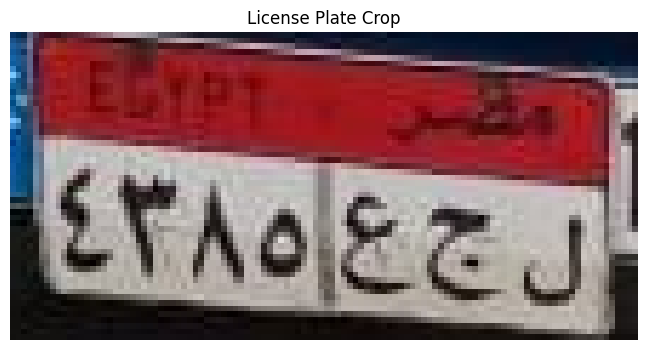

In [31]:
from PIL import Image

image = Image.open(image_path)

x1, y1, x2, y2 = boxes[0].xyxy[0].tolist()

x1, y1, x2, y2 = map(int, [x1, y1, x2, y2])

plate_crop = image.crop((x1, y1, x2, y2))

print("Original image size:", image.size)
print("Plate crop size:", plate_crop.size)
plt.figure(figsize=(12, 4))

plt.imshow(plate_crop)
plt.axis("off")
plt.title("License Plate Crop")

plt.show()

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plate = np.array(plate_crop)

plate_bgr = cv2.cvtColor(plate, cv2.COLOR_RGB2BGR)

print("Plate shape:", plate_bgr.shape)

Plate shape: (54, 110, 3)


In [33]:
scale = 3

plate_resized = cv2.resize(
    plate_bgr,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_CUBIC
)

print("Original:", plate_bgr.shape)
print("Resized:", plate_resized.shape)

Original: (54, 110, 3)
Resized: (162, 330, 3)


In [34]:
gray = cv2.cvtColor(
    plate_resized,
    cv2.COLOR_BGR2GRAY
)

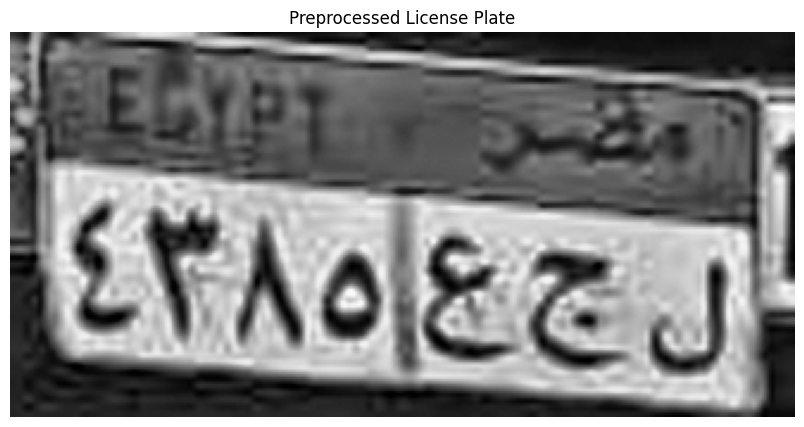

In [36]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)
plt.figure(figsize=(14, 5))

plt.imshow(enhanced, cmap="gray")
plt.axis("off")
plt.title("Preprocessed License Plate")

plt.show()

In [37]:
!pip install easyocr -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 31.2 MB/s eta 0:00:00


In [38]:
import easyocr

reader = easyocr.Reader(
    ['en'],
    gpu=True
)

print("EasyOCR loaded!")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR loaded!


In [39]:
ocr_results = reader.readtext(
    enhanced
)

print("OCR Results:")

for result in ocr_results:
    bbox, text, confidence = result

    print(
        f"Text: {text} | "
        f"Confidence: {confidence:.3f}"
    )

OCR Results:
Text: 03e7 | Confidence: 0.029
Text: EAdeed | Confidence: 0.149


In [40]:
def run_ocr(image, reader):

    results = reader.readtext(image)

    detected_text = []

    for bbox, text, confidence in results:

        detected_text.append({
            "text": text,
            "confidence": confidence
        })

    return detected_text

In [41]:
results = run_ocr(
    enhanced,
    reader
)

for item in results:
    print(item)

{'text': '03e7', 'confidence': np.float64(0.028751971200108528)}
{'text': 'EAdeed', 'confidence': np.float64(0.14865056971030013)}


In [42]:
resized = cv2.resize(
    plate_bgr,
    None,
    fx=3,
    fy=3,
    interpolation=cv2.INTER_CUBIC
)

gray = cv2.cvtColor(
    resized,
    cv2.COLOR_BGR2GRAY
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)

threshold = cv2.threshold(
    enhanced,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)[1]

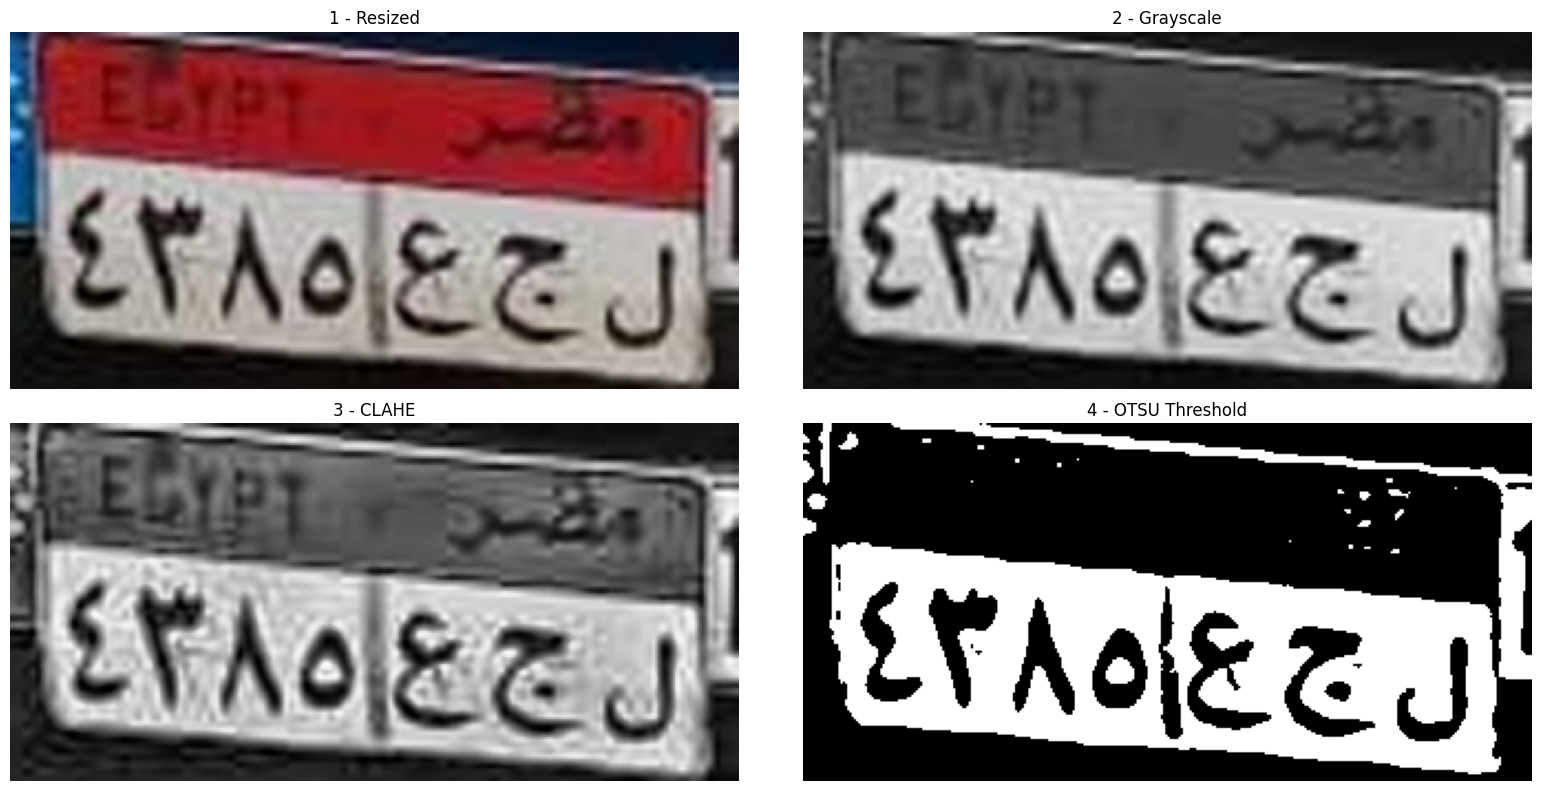

In [43]:
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("1 - Resized")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("2 - Grayscale")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(enhanced, cmap="gray")
plt.title("3 - CLAHE")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(threshold, cmap="gray")
plt.title("4 - OTSU Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()

In [46]:
from pathlib import Path

pt_files = list(Path("/content").rglob("best.pt"))

print("Found models:", len(pt_files))

for i, path in enumerate(pt_files):
    print(i, path)

Found models: 1
0 /content/runs/detect/train/weights/best.pt


In [47]:
from pathlib import Path

for p in Path("/content").iterdir():
    print(p)

/content/.config
/content/runs
/content/weights
/content/egyptian-license-plate-2
/content/sample_data


In [48]:
from pathlib import Path

weights_path = Path("/content/weights")

for p in weights_path.rglob("*"):
    print(p)

/content/weights/yolo26n.pt


In [49]:
from ultralytics import YOLO

vehicle_model = YOLO("/content/weights/yolo26n.pt")

print(vehicle_model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [50]:
from google.colab import files

files.download("/content/weights/yolo26n.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
from google.colab import files

files.download("/content/runs/detect/train/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>